In [3]:
# Import analysis libraries.
import pandas as pd
pd.set_option("display.float_format", lambda x: f"{x:,.2f}") # Set numbers format.
import numpy as np
import scipy.stats as stats

# Import visual libraries.
import matplotlib.pyplot as plt

# Import engine connection file.
from _01_database_connection import engine

The connection is successfully completed!


**Q1: What is the true average daily sales with 95% confidence?**

In [4]:
# Extract the data from the database.
fact_sales = pd.read_sql(
    sql="SELECT * FROM gold.fact_sales",
    con=engine
)

fact_sales.sample(2)

,order_number,product_key,customer_key,order_date,ship_date,due_date,price,quantity,sales
56157,SO73350,10,10507,2013-12-18,2013-12-25,2013-12-30,35,1,35
42470,SO67526,16,2682,2013-10-01,2013-10-08,2013-10-13,35,1,35


In [5]:
# Group the data by daily sales, and order the series by the date ascendingly.
daily_grouped_revenue = fact_sales.groupby(
    by="order_date"
)["sales"].sum().sort_index(ascending=True)

daily_grouped_revenue

order_date
2011-01-01     7156
2011-01-02    15011
2011-01-03    14312
2011-01-04     7855
2011-01-05     7855
              ...  
2014-01-24     1498
2014-01-25     1744
2014-01-26     1845
2014-01-27     1477
2014-01-28     2642
Name: sales, Length: 1121, dtype: int64

In [6]:
# Describe the data.
daily_grouped_revenue.describe()


count    1,121.00
mean    26,144.37
std     17,307.44
min        699.00
25%     13,931.00
50%     21,265.00
75%     35,602.00
max     96,600.00
Name: sales, dtype: float64

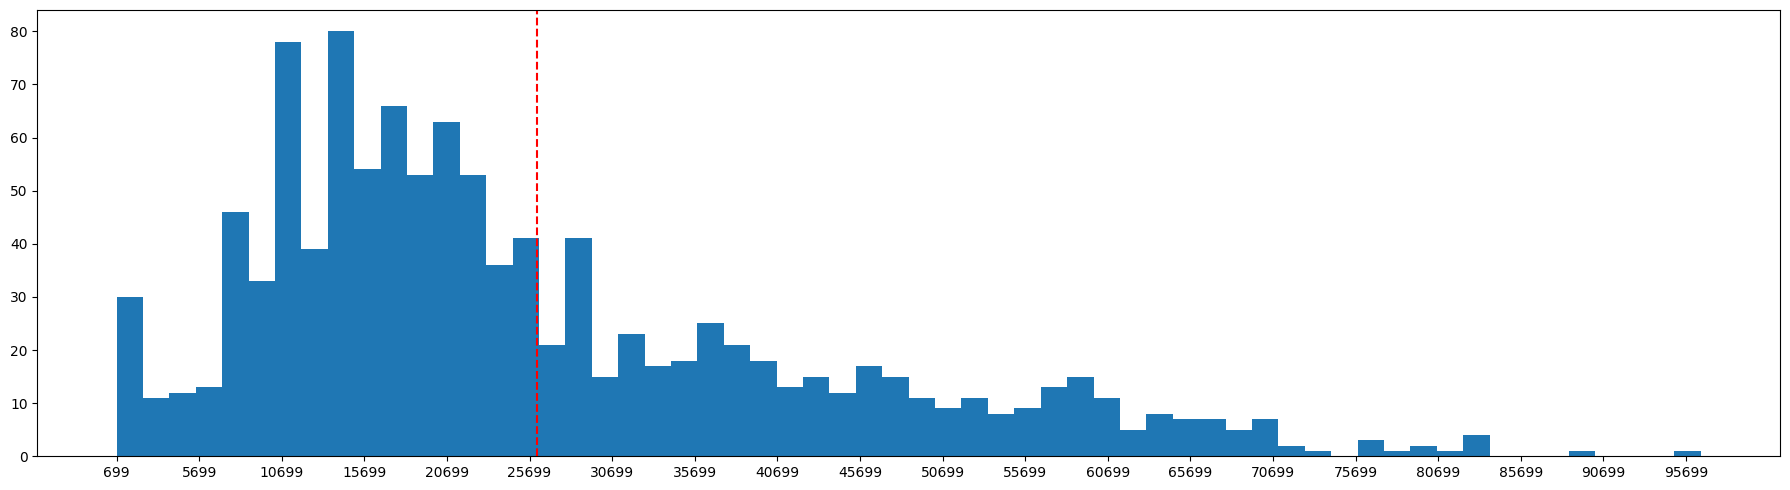

In [7]:
# Visual and check the distribution of the data.
daily_grouped_revenue.hist(bins=60, figsize=(18, 5));

plt.xticks(np.arange(daily_grouped_revenue.min(), daily_grouped_revenue.max(), 5000));
plt.axvline(daily_grouped_revenue.mean(), ls="--", color="r"); # Mean line.
plt.grid(False);
plt.tight_layout();
# The distribution shows there is right skewness of the daily revenue.

In [8]:
# We will use t-distribution because, the std of the population is unknown.

# Apply the t-test manually.
mean = np.mean(daily_grouped_revenue)
s = np.std(a=daily_grouped_revenue, ddof=1)
n = len(daily_grouped_revenue)

# Calculate degree of freedom.
df = n - 1

# Calculate the area under the curve with 0.95 confidence interval (two tailed test).
critical_t = stats.t.ppf(q=.975, df=df)

# Calculate the Standard Error(SE).
SE = (s / np.sqrt(n))

# Calculate margin of error (ME).
ME = critical_t * SE

# Calculate upper and lower bound.
upper = mean + ME
lower = mean - ME

CI = [lower, upper]
print(f"We are confident 95% that the true mean falls between {CI[0]:,.0f}$ and {CI[1]:,.0f}$")

We are confident 95% that the true mean falls between 25,130$ and 27,159$


In [9]:
# Calculate confidence interval by the reday function.
stats.t.interval(0.95, df, mean, SE)

(np.float64(25130.113857253145), np.float64(27158.62655309476))

**Q2: Is this average still reliable if sales are not normally distributed?**

In [10]:
# Apply bootstrap method manually.
np.random.seed(45) # To be constant.

def bootstrap(data, B, q):

    sample_means = np.zeros(B) # Create a zeros array to contain means of sampling.
    n = len(data) # Numner of observations.

    # Divide the difference between 100 and q by 2
    alpha = (100 - q) / 2

    # Cut alpha value from the boundries.
    upper_q = 100 - alpha
    lower_q = alpha

    for i in range(B):
        sample = np.random.choice(a=data, size=n, replace=True) # Make n samples from the data with replacement.
        sample_means[i] = sample.mean() # Append mean of the sample in the array.

    lower_bound = np.percentile(a=sample_means, q=lower_q)
    upper_bound = np.percentile(a=sample_means, q=upper_q)
    return f"{lower_bound:,.0f} and {upper_bound:,.0f}"

bootstrap(data=daily_grouped_revenue, B=5000, q=95)

'25,140 and 27,188'

**Q3: Is management's claim of $28,000 average daily sales statistically valid?**

In [13]:
# Hypothesis
# H0: mu = 28000
# Ha: mu != 28000 (two-sided)
claimed_mean = 28000
alpha = 0.05

# One-sample t-test
t_stat, p_value = stats.ttest_1samp(daily_grouped_revenue, popmean=claimed_mean)

print(f"Sample Mean: {mean:.2f}")
print(f"Sample Size: {n}")
print(f"Claimed Mean (H0): {claimed_mean}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

# If p_value < alpha, Reject H0 otherwise fail to reject.
if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Sample Mean: 26144.37
Sample Size: 1121
Claimed Mean (H0): 28000
T-statistic: -3.5897
P-value: 0.000345
Reject H0
